# Nonlinear Driven Pendulum and Sensitivity to Initial Conditions

This project numerically studies a damped, driven nonlinear pendulum and investigates its sensitivity to nearby initial conditions.

The governing equation is:

$$
\ddot{\theta} + q\dot{\theta} + \sin(\theta)
= F_D\cos(\Omega_D t)
$$

The numerical results are used to compare two nearby trajectories and study how their separation depends on the driving amplitude.

## Physical Model

The driven pendulum is a nonlinear dynamical system subject to damping and periodic external forcing.

- The term $\sin(\theta)$ represents the nonlinear gravitational restoring effect.
- The damping coefficient $q$ describes energy dissipation.
- The driving amplitude $F_D$ controls the strength of the external force.
- The driving frequency $\Omega_D$ determines how rapidly the external force oscillates.
- The system's future motion depends on its parameters and initial conditions.
- Two initially close trajectories can evolve differently over time.
- This project numerically investigates this sensitivity and how it changes with the driving amplitude.

## Numerical Method

The equation of motion is rewritten as a system of two first-order ordinary differential equations by defining the angular velocity as $\omega = \dot{\theta}$.

$$
\dot{\theta} = \omega
$$

$$
\dot{\omega} = -q\omega - \sin(\theta) + F_D\cos(\Omega_D t)
$$

The system is solved numerically using SciPy's `solve_ivp` function. Two nearby initial conditions are used to compare the resulting trajectories.

## Implementation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

The model parameters and initial conditions are defined below. The damping coefficient is $q = 0.5$, the driving amplitude is $F_D = 1.2$, and the driving frequency is $\Omega_D = 2/3$.

The two trajectories start with slightly different angular positions, $\theta_1(0) = 0.2$ and $\theta_2(0) = 0.200001$, while both have the same initial angular velocity, $\omega(0) = 0$.

The time interval is $0 \leq t \leq 100$, sampled at 10,000 points.

In [2]:
def driven_pendulum(t, state, q, F_D, Omega_D):
    theta, omega = state

    dtheta_dt = omega
    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    return [dtheta_dt, domega_dt]

In [3]:
q = 0.5
F_D = 1.2
Omega_D = 2 / 3

theta_1_0 = 0.2
theta_2_0 = 0.200001
omega_0 = 0.0

state_1_0 = [theta_1_0, omega_0]
state_2_0 = [theta_2_0, omega_0]

In [4]:

t_start = 0.0
t_end = 100.0
num_points = 10000

t_eval = np.linspace(t_start, t_end, num_points)

In [5]:

solution_1 = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_1_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)

solution_2 = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_2_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-9,
    atol=1e-11
)


In [6]:

print("Solution 1 successful:", solution_1.success)
print("Solution 2 successful:", solution_2.success)

print("Solution 1 shape:", solution_1.y.shape)
print("Solution 2 shape:", solution_2.y.shape)

print("Time arrays match:", np.array_equal(solution_1.t, solution_2.t))


Solution 1 successful: True
Solution 2 successful: True
Solution 1 shape: (2, 10000)
Solution 2 shape: (2, 10000)
Time arrays match: True


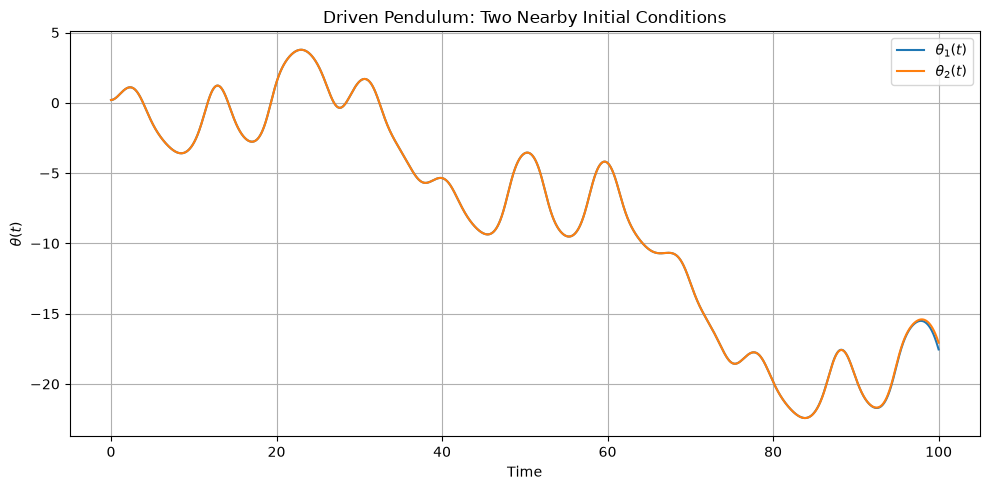

In [7]:

plt.figure(figsize=(10, 5))

plt.plot(
    solution_1.t,
    solution_1.y[0],
    label=r"$\theta_1(t)$"
)

plt.plot(
    solution_2.t,
    solution_2.y[0],
    label=r"$\theta_2(t)$"
)

plt.xlabel("Time")
plt.ylabel(r"$\theta(t)$")
plt.title("Driven Pendulum: Two Nearby Initial Conditions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [8]:

difference = np.abs(solution_1.y[0] - solution_2.y[0])

print("Initial difference:", difference[0])
print("Maximum difference:", np.max(difference))
print("Final difference:", difference[-1])


Initial difference: 1.000000000001e-06
Maximum difference: 0.48065137874876385
Final difference: 0.48065137874876385


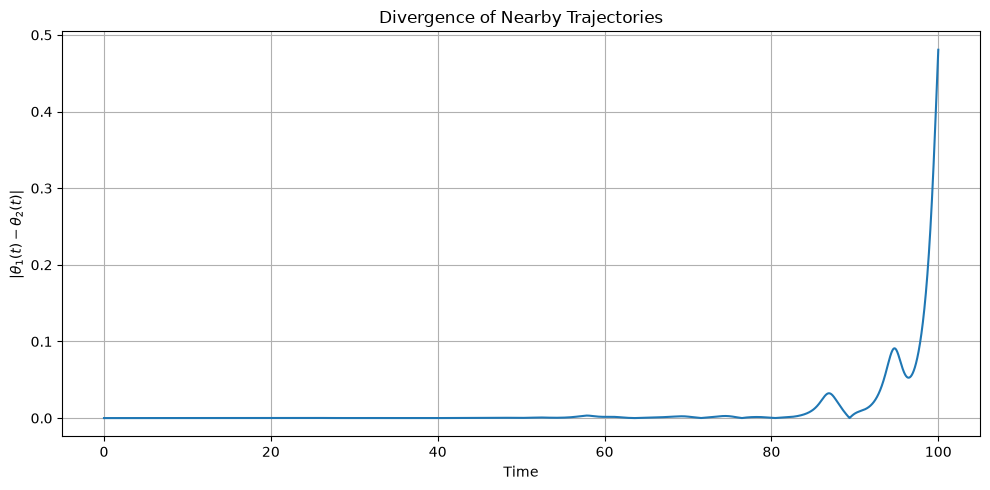

In [9]:

plt.figure(figsize=(10, 5))

plt.plot(solution_1.t, difference)

plt.xlabel("Time")
plt.ylabel(r"$|\theta_1(t)-\theta_2(t)|$")
plt.title("Divergence of Nearby Trajectories")
plt.grid(True)
plt.tight_layout()
plt.show()


In [10]:

thresholds = [0.01, 0.05, 0.10, 0.20]

for threshold in thresholds:
    indices = np.where(difference >= threshold)[0]

    if len(indices) > 0:
        first_index = indices[0]
        print(
            f"Difference first reaches {threshold:.2f} "
            f"at t = {solution_1.t[first_index]:.4f}"
        )
    else:
        print(
            f"Difference never reaches {threshold:.2f}"
        )


Difference first reaches 0.01 at t = 84.8885
Difference first reaches 0.05 at t = 93.4693
Difference first reaches 0.10 at t = 97.8498
Difference first reaches 0.20 at t = 98.7799


## Parameter Study

To investigate the effect of the driving amplitude, $F_D$ is varied while the damping coefficient, driving frequency, initial conditions, and time interval are kept fixed.

For each value of $F_D$, both trajectories are solved numerically, and the maximum absolute angular difference over the simulation interval is calculated.

This comparison shows how the observed sensitivity to initial conditions depends on the driving amplitude for the selected parameters and simulation time.

In [11]:

F_D_values = np.arange(0.8, 1.4001, 0.05)

max_differences = []
success_flags = []


In [12]:

for F_D_test in F_D_values:
    sol_1 = solve_ivp(
        driven_pendulum,
        (t_start, t_end),
        state_1_0,
        args=(q, F_D_test, Omega_D),
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11
    )

    sol_2 = solve_ivp(
        driven_pendulum,
        (t_start, t_end),
        state_2_0,
        args=(q, F_D_test, Omega_D),
        t_eval=t_eval,
        rtol=1e-9,
        atol=1e-11
    )

    difference_test = np.abs(sol_1.y[0] - sol_2.y[0])

    max_differences.append(np.max(difference_test))
    success_flags.append(sol_1.success and sol_2.success)

print("All parameter-study solves successful:", all(success_flags))


All parameter-study solves successful: True


In [13]:

for F_D_test, max_difference in zip(
    F_D_values, max_differences
):
    print(
        f"F_D = {F_D_test:.2f} -> "
        f"maximum difference = {max_difference:.6f}"
    )


F_D = 0.80 -> maximum difference = 0.000001
F_D = 0.85 -> maximum difference = 0.000001
F_D = 0.90 -> maximum difference = 0.000001
F_D = 0.95 -> maximum difference = 0.000001
F_D = 1.00 -> maximum difference = 0.000002
F_D = 1.05 -> maximum difference = 0.000074
F_D = 1.10 -> maximum difference = 0.000012
F_D = 1.15 -> maximum difference = 0.297652
F_D = 1.20 -> maximum difference = 0.480651
F_D = 1.25 -> maximum difference = 0.089702
F_D = 1.30 -> maximum difference = 0.000001
F_D = 1.35 -> maximum difference = 0.000001
F_D = 1.40 -> maximum difference = 0.000001


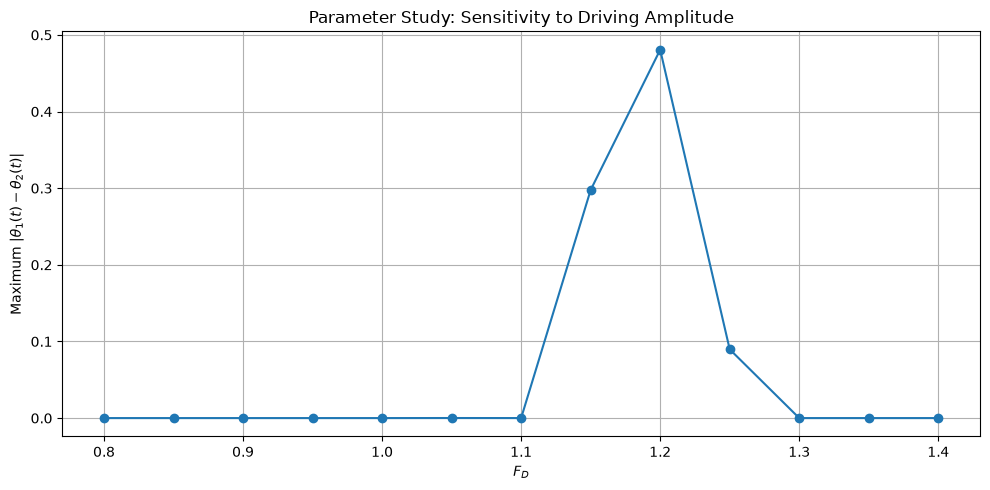

In [14]:

plt.figure(figsize=(10, 5))

plt.plot(
    F_D_values,
    max_differences,
    marker="o"
)

plt.xlabel(r"$F_D$")
plt.ylabel(r"Maximum $|\theta_1(t)-\theta_2(t)|$")
plt.title("Parameter Study: Sensitivity to Driving Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()


## Conclusion

The numerical simulations compared two trajectories with nearly identical initial conditions. Their initial angular difference was approximately $10^{-6}$, but for the selected parameters, the difference increased to approximately $0.481$ by $t=100$.

The parameter study showed that the maximum trajectory separation varied with the driving amplitude. The largest separation in the tested values occurred at $F_D=1.20$, with a maximum difference of approximately $0.481$.

These results provide numerical evidence of sensitivity to initial conditions for the selected parameters and simulation interval. However, trajectory separation alone does not establish mathematical chaos; further analysis, such as calculating a Lyapunov exponent, would be needed for a stronger conclusion.

## Model Limitations

1. **Simplified physical model:** The model assumes linear damping and sinusoidal external forcing. It does not account for other physical effects, such as nonlinear friction, variations in the forcing, or measurement noise.

2. **Limited evidence for chaos:** The divergence of two nearby trajectories does not, by itself, prove that the system is chaotic. A more rigorous investigation would require additional methods, such as estimating the largest Lyapunov exponent or analyzing a Poincaré section.

## Numerical Validation

To assess the numerical robustness of the simulation, the equations are solved again using both relaxed and stricter solver tolerances. The resulting maximum trajectory separations are compared with the original calculation.

The integration interval and initial conditions are also checked to confirm that both trajectories cover the full simulation interval. These checks help assess numerical consistency, but they do not independently establish whether the system is chaotic.

In [15]:

solution_1_check = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_1_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-7,
    atol=1e-9
)

solution_2_check = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_2_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-7,
    atol=1e-9
)

difference_check = np.abs(
    solution_1_check.y[0] - solution_2_check.y[0]
)

print("Both solves successful:",
      solution_1_check.success and solution_2_check.success)

print("Maximum difference with original tolerances:",
      np.max(difference))

print("Maximum difference with relaxed tolerances:",
      np.max(difference_check))


Both solves successful: True
Maximum difference with original tolerances: 0.48065137874876385
Maximum difference with relaxed tolerances: 0.5067338426655148


In [16]:

solution_1_strict = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_1_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-11,
    atol=1e-13
)

solution_2_strict = solve_ivp(
    driven_pendulum,
    (t_start, t_end),
    state_2_0,
    args=(q, F_D, Omega_D),
    t_eval=t_eval,
    rtol=1e-11,
    atol=1e-13
)

difference_strict = np.abs(
    solution_1_strict.y[0] - solution_2_strict.y[0]
)

print(
    "Both strict solves successful:",
    solution_1_strict.success and solution_2_strict.success
)

print(
    "Maximum difference with strict tolerances:",
    np.max(difference_strict)
)


Both strict solves successful: True
Maximum difference with strict tolerances: 0.4803362327803846


In [17]:

print("Strict solution 1 final time:", solution_1_strict.t[-1])
print("Strict solution 2 final time:", solution_2_strict.t[-1])
print("Expected final time:", t_end)

print(
    "Both solutions cover the full time interval:",
    solution_1_strict.t[-1] == t_end
    and solution_2_strict.t[-1] == t_end
)


Strict solution 1 final time: 100.0
Strict solution 2 final time: 100.0
Expected final time: 100.0
Both solutions cover the full time interval: True


In [18]:

print("Number of driving amplitudes:", len(F_D_values))
print("Number of recorded differences:", len(max_differences))
print("Number of solve-status records:", len(success_flags))
print("All parameter-study solves successful:", all(success_flags))


Number of driving amplitudes: 13
Number of recorded differences: 13
Number of solve-status records: 13
All parameter-study solves successful: True


In [27]:
# Parameters for Lyapunov exponent calculation

delta_0 = 1e-8       # Initial perturbation
renorm_time = 0.1   # Time interval between renormalizations
total_time = 2000.0  # Total simulation time

# Initial state
initial_state = np.array([0.2, 0.0])

# Perturbed initial state
perturbed_state = initial_state + np.array([delta_0, 0.0])

print("Initial state:", initial_state)
print("Perturbed state:", perturbed_state)

print("Initial separation:",
      np.linalg.norm(perturbed_state - initial_state))

Initial state: [0.2 0. ]
Perturbed state: [0.20000001 0.        ]
Initial separation: 9.999999994736442e-09


In [28]:
from scipy.integrate import solve_ivp
import numpy as np

# Model parameters
q = 0.5
F_D = 1.2
Omega_D = 2 / 3

# Initialize states
state_1 = initial_state.copy()
state_2 = perturbed_state.copy()

# Lyapunov exponent calculation
sum_log_growth = 0.0
num_steps = int(total_time / renorm_time)

for i in range(num_steps):

    t_start = i * renorm_time
    t_end = (i + 1) * renorm_time

    sol_1 = solve_ivp(
        driven_pendulum,
        (t_start, t_end),
        state_1,
        args=(q, F_D, Omega_D),
        rtol=1e-9,
        atol=1e-11
    )

    sol_2 = solve_ivp(
        driven_pendulum,
        (t_start, t_end),
        state_2,
        args=(q, F_D, Omega_D),
        rtol=1e-9,
        atol=1e-11
    )

    state_1 = sol_1.y[:, -1]
    state_2 = sol_2.y[:, -1]

    # Calculate separation
    difference = state_2 - state_1
    distance = np.linalg.norm(difference)

    # Accumulate logarithmic growth
    sum_log_growth += np.log(distance / delta_0)

    # Renormalize the perturbation
    state_2 = state_1 + delta_0 * difference / distance

# Estimate the largest Lyapunov exponent
lyapunov_exponent = sum_log_growth / total_time

print("Largest Lyapunov Exponent:", lyapunov_exponent)

Largest Lyapunov Exponent: 0.1274367745423191


In [29]:
def variational_system(t, Y, q, F_D, Omega_D):
    theta, omega, dtheta, domega = Y

    # Original pendulum equations
    dtheta_dt = omega
    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    # Variational equations
    ddtheta_dt = domega
    ddomega_dt = (
        -np.cos(theta) * dtheta
        - q * domega
    )

    return [
        dtheta_dt,
        domega_dt,
        ddtheta_dt,
        ddomega_dt
    ]

In [52]:
def calculate_lyapunov_variational(
    q, F_D, Omega_D,
    initial_state,
    delta_0=1e-9,
    renorm_time=0.1,
    transient_time=1000.0,
    total_time=40000.0
):
    state = np.array(initial_state, dtype=float)

    # Step 1: Remove the initial transient
    transient_sol = solve_ivp(
        driven_pendulum,
        (0, transient_time),
        state,
        args=(q, F_D, Omega_D),
        rtol=1e-9,
        atol=1e-11
    )

    if not transient_sol.success:
        raise RuntimeError(transient_sol.message)

    # State after the transient
    state = transient_sol.y[:, -1]

    # Step 2: Initialize a small perturbation
    perturbation = np.array([1.0, 0.0])

    sum_log_growth = 0.0
    num_steps = int(total_time / renorm_time)

    # Step 3: Calculate Lyapunov exponent
    for i in range(num_steps):
        t_start = transient_time + i * renorm_time
        t_end = transient_time + (i + 1) * renorm_time

        Y0 = np.concatenate([state, perturbation])

        sol = solve_ivp(
            variational_system,
            (t_start, t_end),
            Y0,
            args=(q, F_D, Omega_D),
            rtol=1e-9,
            atol=1e-11
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        state = sol.y[:2, -1]
        perturbation = sol.y[2:, -1]

        distance = np.linalg.norm(perturbation)

        if distance == 0 or not np.isfinite(distance):
            raise RuntimeError("Invalid perturbation magnitude")

        sum_log_growth += np.log(distance)

        perturbation = perturbation / distance

    return sum_log_growth / (num_steps * renorm_time)

In [53]:
# Model parameters
q = 0.5
F_D = 1.2
Omega_D = 2 / 3

# Initial condition
initial_state = [0.2, 0.0]

# Calculate largest Lyapunov exponent
lyapunov = calculate_lyapunov_variational(
    q=0.5,
    F_D=1.2,
    Omega_D=2/3,
    initial_state=[0.2, 0.0],
    delta_0=1e-9,
    renorm_time=0.1,
    transient_time=1000.0,
    total_time=40000.0
)

print("Largest Lyapunov Exponent:", lyapunov)

Largest Lyapunov Exponent: 0.13205773499697954


In [54]:
# Driving period
T_D = 2 * np.pi / Omega_D

print("Driving period:", T_D)

Driving period: 9.42477796076938


In [55]:
# Poincare section parameters
transient_time = 1000.0
num_points = 2000

# Sampling times
sampling_times = (
    transient_time
    + np.arange(1, num_points + 1) * T_D
)

# Initial conditions
initial_state = [0.2, 0.0]

# Integrate the system
poincare_sol = solve_ivp(
    driven_pendulum,
    (0, sampling_times[-1]),
    initial_state,
    args=(q, F_D, Omega_D),
    t_eval=sampling_times,
    rtol=1e-9,
    atol=1e-11
)

if not poincare_sol.success:
    raise RuntimeError(poincare_sol.message)

# Extract Poincare points
theta_poincare = poincare_sol.y[0]
omega_poincare = poincare_sol.y[1]

print("Number of Poincare points:", len(theta_poincare))
print("First 5 theta values:", theta_poincare[:5])
print("First 5 omega values:", omega_poincare[:5])

Number of Poincare points: 2000
First 5 theta values: [27.30777819 26.50336593 19.80525066 19.52966793 20.43907174]
First 5 omega values: [0.89931767 1.28880212 0.0205811  2.21834858 1.68785055]


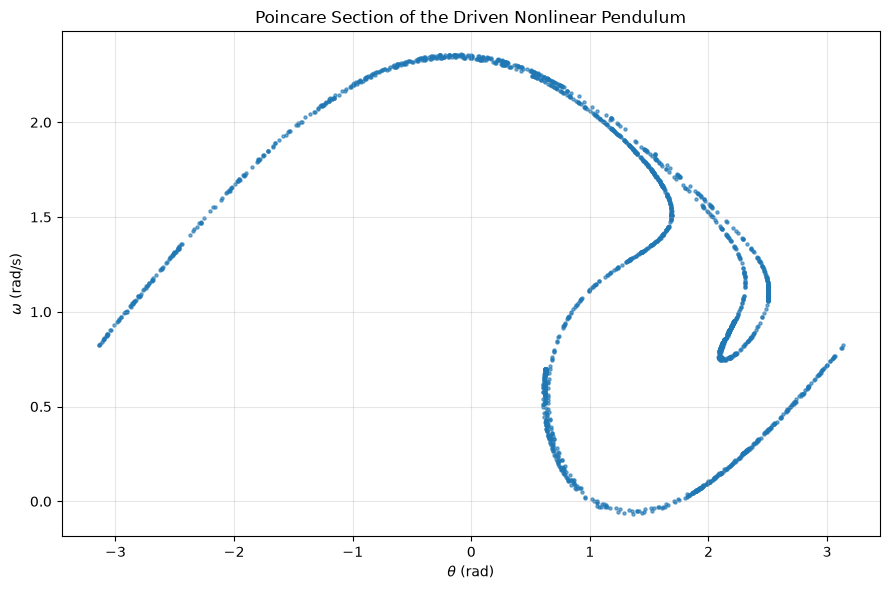

In [56]:
# Wrap angular positions to [-pi, pi]
theta_wrapped = (theta_poincare + np.pi) % (2 * np.pi) - np.pi

# Plot Poincare section
plt.figure(figsize=(9, 6))

plt.scatter(
    theta_wrapped,
    omega_poincare,
    s=5,
    alpha=0.6
)

plt.xlabel(r'$\theta$ (rad)')
plt.ylabel(r'$\omega$ (rad/s)')
plt.title('Poincare Section of the Driven Nonlinear Pendulum')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

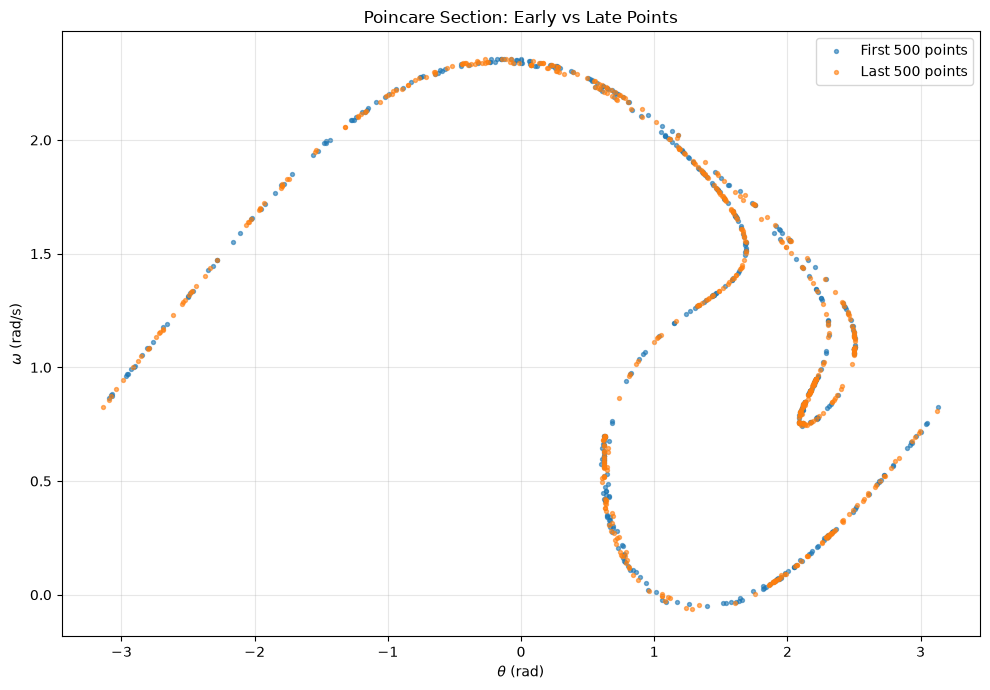

In [57]:
plt.figure(figsize=(10, 7))

plt.scatter(
    theta_wrapped[:500],
    omega_poincare[:500],
    s=8,
    alpha=0.6,
    label="First 500 points"
)

plt.scatter(
    theta_wrapped[-500:],
    omega_poincare[-500:],
    s=8,
    alpha=0.6,
    label="Last 500 points"
)

plt.xlabel(r'$\theta$ (rad)')
plt.ylabel(r'$\omega$ (rad/s)')
plt.title('Poincare Section: Early vs Late Points')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
def calculate_lyapunov_two_trajectories(
    q,
    F_D,
    Omega_D,
    initial_state,
    delta_0=1e-8,
    renorm_time=0.05,
    transient_time=1000.0,
    total_time=5000.0
):
    # First remove the transient
    transient_sol = solve_ivp(
        driven_pendulum,
        (0, transient_time),
        initial_state,
        args=(q, F_D, Omega_D),
        rtol=1e-9,
        atol=1e-11
    )

    if not transient_sol.success:
        raise RuntimeError(transient_sol.message)

    reference_state = transient_sol.y[:, -1].copy()

    # Initial nearby trajectory
    perturbed_state = (
        reference_state
        + np.array([delta_0, 0.0])
    )

    sum_log_growth = 0.0

    num_steps = int(total_time / renorm_time)

    for i in range(num_steps):

        t_start = transient_time + i * renorm_time
        t_end = transient_time + (i + 1) * renorm_time

        # Reference trajectory
        sol_ref = solve_ivp(
            driven_pendulum,
            (t_start, t_end),
            reference_state,
            args=(q, F_D, Omega_D),
            rtol=1e-9,
            atol=1e-11
        )

        # Perturbed trajectory
        sol_pert = solve_ivp(
            driven_pendulum,
            (t_start, t_end),
            perturbed_state,
            args=(q, F_D, Omega_D),
            rtol=1e-9,
            atol=1e-11
        )

        if not sol_ref.success or not sol_pert.success:
            raise RuntimeError("Integration failed")

        reference_state = sol_ref.y[:, -1]
        perturbed_state = sol_pert.y[:, -1]

        # Separation between trajectories
        difference = perturbed_state - reference_state
        distance = np.linalg.norm(difference)

        if distance == 0 or not np.isfinite(distance):
            raise RuntimeError("Invalid trajectory separation")

        # Accumulate logarithmic growth
        sum_log_growth += np.log(distance / delta_0)

        # Renormalize perturbation
        difference = delta_0 * difference / distance

        perturbed_state = reference_state + difference

    return sum_log_growth / (num_steps * renorm_time)

In [3]:
from scipy.integrate import solve_ivp

In [5]:
import numpy as np

In [6]:
def driven_pendulum(t, y, q, F_D, Omega_D):
    theta, omega = y

    dtheta_dt = omega
    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    return [dtheta_dt, domega_dt]

In [7]:
lyapunov_two = calculate_lyapunov_two_trajectories(
    q=0.5,
    F_D=1.2,
    Omega_D=2/3,
    initial_state=[0.2, 0.0],
    delta_0=1e-8,
    renorm_time=0.05,
    transient_time=1000.0,
    total_time=5000.0
)

print("Largest Lyapunov Exponent (two trajectories):", lyapunov_two)

Largest Lyapunov Exponent (two trajectories): 0.1325117295436108


In [11]:
import numpy as np
import matplotlib.pyplot as plt

q = 0.5
F_D = 1.2
Omega_D = 2 / 3

print(q, F_D, Omega_D)

0.5 1.2 0.6666666666666666


In [12]:
def driven_pendulum(t, y, q, F_D, Omega_D):
    theta, omega = y

    dtheta_dt = omega

    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    return [dtheta_dt, domega_dt]

In [13]:
T_D = 2 * np.pi / Omega_D

transient_time = 1000.0
num_points = 2000

sampling_times = (
    transient_time
    + np.arange(1, num_points + 1) * T_D
)

poincare_sol = solve_ivp(
    driven_pendulum,
    (0, sampling_times[-1]),
    [0.2, 0.0],
    args=(q, F_D, Omega_D),
    t_eval=sampling_times,
    rtol=1e-9,
    atol=1e-11
)

theta_poincare = poincare_sol.y[0]
omega_poincare = poincare_sol.y[1]

theta_wrapped = (
    (theta_poincare + np.pi) % (2 * np.pi)
    - np.pi
)

print("Number of Poincare points:", len(theta_wrapped))

Number of Poincare points: 2000


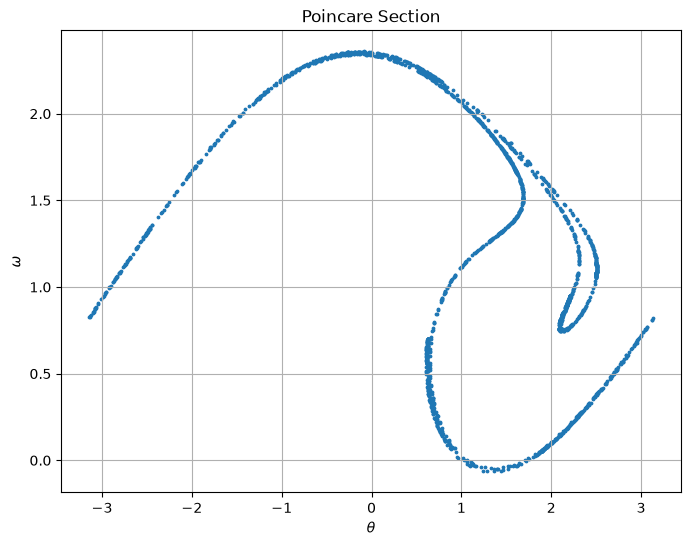

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(
    theta_wrapped,
    omega_poincare,
    s=3
)

plt.xlabel(r"$\theta$")
plt.ylabel(r"$\omega$")
plt.title("Poincare Section")
plt.grid(True)

plt.show()

In [15]:
def calculate_lyapunov_poincare(
    q,
    F_D,
    Omega_D,
    initial_state,
    delta_0=1e-8,
    transient_time=1000.0,
    num_periods=1000
):
    T_D = 2 * np.pi / Omega_D

    # Remove transient
    transient_sol = solve_ivp(
        driven_pendulum,
        (0, transient_time),
        initial_state,
        args=(q, F_D, Omega_D),
        rtol=1e-9,
        atol=1e-11
    )

    if not transient_sol.success:
        raise RuntimeError(transient_sol.message)

    reference_state = transient_sol.y[:, -1].copy()
    perturbed_state = (
        reference_state + np.array([delta_0, 0.0])
    )

    sum_log_growth = 0.0

    for i in range(num_periods):

        t_start = transient_time + i * T_D
        t_end = transient_time + (i + 1) * T_D

        sol_ref = solve_ivp(
            driven_pendulum,
            (t_start, t_end),
            reference_state,
            args=(q, F_D, Omega_D),
            rtol=1e-9,
            atol=1e-11
        )

        sol_pert = solve_ivp(
            driven_pendulum,
            (t_start, t_end),
            perturbed_state,
            args=(q, F_D, Omega_D),
            rtol=1e-9,
            atol=1e-11
        )

        if not sol_ref.success or not sol_pert.success:
            raise RuntimeError("Integration failed")

        reference_state = sol_ref.y[:, -1]
        perturbed_state = sol_pert.y[:, -1]

        difference = perturbed_state - reference_state
        distance = np.linalg.norm(difference)

        if distance == 0 or not np.isfinite(distance):
            raise RuntimeError("Invalid trajectory separation")

        sum_log_growth += np.log(distance / delta_0)

        difference = delta_0 * difference / distance
        perturbed_state = reference_state + difference

    total_time = num_periods * T_D

    return sum_log_growth / total_time

In [16]:
lyapunov_poincare = calculate_lyapunov_poincare(
    q=0.5,
    F_D=1.2,
    Omega_D=2/3,
    initial_state=[0.2, 0.0],
    delta_0=1e-8,
    transient_time=1000.0,
    num_periods=1000
)

print(
    "Largest Lyapunov Exponent (Poincare-period renormalization):",
    lyapunov_poincare
)

Largest Lyapunov Exponent (Poincare-period renormalization): 0.1302267809887243


In [17]:
def full_variational_system(t, Y, q, F_D, Omega_D):

    theta, omega = Y[:2]

    V = Y[2:].reshape((2, 2))

    # Original system
    dtheta_dt = omega

    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    # Jacobian matrix
    J = np.array([
        [0.0, 1.0],
        [-np.cos(theta), -q]
    ])

    # Evolution of perturbation vectors
    dV_dt = J @ V

    return np.concatenate((
        [dtheta_dt, domega_dt],
        dV_dt.flatten()
    ))

In [6]:

def calculate_full_lyapunov_spectrum(
    q,
    F_D,
    Omega_D,
    initial_state,
    transient_time=1000.0,
    total_time=10000.0,
    renorm_time=0.05
):
    state = np.array(initial_state, dtype=float)

    # Remove the transient
    transient_sol = solve_ivp(
        driven_pendulum,
        (0, transient_time),
        state,
        args=(q, F_D, Omega_D),
        rtol=1e-9,
        atol=1e-11
    )

    if not transient_sol.success:
        raise RuntimeError(transient_sol.message)

    state = transient_sol.y[:, -1]

    # Initialize two orthonormal perturbation vectors
    V = np.eye(2)

    sum_log_growth = np.zeros(2)

    num_steps = int(total_time / renorm_time)

    for i in range(num_steps):

        t_start = transient_time + i * renorm_time
        t_end = transient_time + (i + 1) * renorm_time

        Y0 = np.concatenate((state, V.flatten()))

        sol = solve_ivp(
            full_variational_system,
            (t_start, t_end),
            Y0,
            args=(q, F_D, Omega_D),
            rtol=1e-11,
            atol=1e-13
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        state = sol.y[:2, -1]
        V = sol.y[2:, -1].reshape((2, 2))

        # QR decomposition
        Q, R = np.linalg.qr(V)

        diagonal = np.abs(np.diag(R))

        if np.any(diagonal == 0) or not np.all(np.isfinite(diagonal)):
            raise RuntimeError("Invalid QR diagonal values")

        sum_log_growth += np.log(diagonal)

        V = Q

    lyapunov_exponents = sum_log_growth / (num_steps * renorm_time)

    return lyapunov_exponents


In [8]:
lyapunov_spectrum = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=F_D,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=1000.0,
    total_time=10000.0,
    renorm_time=0.05
)

print("Lyapunov Spectrum:")
print("Lambda 1 =", lyapunov_spectrum[0])
print("Lambda 2 =", lyapunov_spectrum[1])
print("Sum =", np.sum(lyapunov_spectrum))

NameError: name 'q' is not defined

In [26]:
spectrum_20000 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=F_D,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=1000.0,
    total_time=20000.0,
    renorm_time=0.05
)

print("Lyapunov Spectrum (T = 20000):")
print("Lambda 1 =", spectrum_20000[0])
print("Lambda 2 =", spectrum_20000[1])
print("Sum =", np.sum(spectrum_20000))

Lyapunov Spectrum (T = 20000):
Lambda 1 = 0.12894522010143328
Lambda 2 = -0.6289452201003531
Sum = -0.49999999999891986


In [27]:
lambda_1 = spectrum_20000[0]
lambda_2 = spectrum_20000[1]

D_KY = 1 + lambda_1 / abs(lambda_2)

print("Kaplan-Yorke Dimension =", D_KY)

Kaplan-Yorke Dimension = 1.2050182050526739


In [28]:
spectrum_renorm_01 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=F_D,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=1000.0,
    total_time=20000.0,
    renorm_time=0.1
)

print("Lyapunov Spectrum (renorm_time = 0.1):")
print("Lambda 1 =", spectrum_renorm_01[0])
print("Lambda 2 =", spectrum_renorm_01[1])
print("Sum =", np.sum(spectrum_renorm_01))

Lyapunov Spectrum (renorm_time = 0.1):
Lambda 1 = 0.13458057511188778
Lambda 2 = -0.6345805751106647
Sum = -0.49999999999877687


In [29]:
spectrum_renorm_0025 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=F_D,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=1000.0,
    total_time=20000.0,
    renorm_time=0.025
)

print("Lyapunov Spectrum (renorm_time = 0.025):")
print("Lambda 1 =", spectrum_renorm_0025[0])
print("Lambda 2 =", spectrum_renorm_0025[1])
print("Sum =", np.sum(spectrum_renorm_0025))

Lyapunov Spectrum (renorm_time = 0.025):
Lambda 1 = 0.13065591893649703
Lambda 2 = -0.6306559189355159
Sum = -0.49999999999901884


In [30]:
spectrum_strict = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=F_D,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=1000.0,
    total_time=20000.0,
    renorm_time=0.05
)

print("Lyapunov Spectrum (strict tolerances):")
print("Lambda 1 =", spectrum_strict[0])
print("Lambda 2 =", spectrum_strict[1])
print("Sum =", np.sum(spectrum_strict))

Lyapunov Spectrum (strict tolerances):
Lambda 1 = 0.12894522010143328
Lambda 2 = -0.6289452201003531
Sum = -0.49999999999891986


In [31]:
spectrum_strict_40000 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=F_D,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=1000.0,
    total_time=40000.0,
    renorm_time=0.05
)

print("Lyapunov Spectrum (strict, T = 40000):")
print("Lambda 1 =", spectrum_strict_40000[0])
print("Lambda 2 =", spectrum_strict_40000[1])
print("Sum =", np.sum(spectrum_strict_40000))

Lyapunov Spectrum (strict, T = 40000):
Lambda 1 = 0.13089298935563776
Lambda 2 = -0.6308929893545785
Sum = -0.49999999999894074


In [32]:
lambda_1 = spectrum_strict_40000[0]
lambda_2 = spectrum_strict_40000[1]

D_KY_strict = 1 + lambda_1 / abs(lambda_2)

print("Kaplan-Yorke Dimension (strict, T=40000):")
print(D_KY_strict)

Kaplan-Yorke Dimension (strict, T=40000):
1.2074725691428987


In [34]:
results = [
    ("Baseline", 20000, 0.05, 1e-9, 1e-11,
     0.13471806461564986, -0.6347180645689997),

    ("Renorm = 0.025", 20000, 0.025, 1e-9, 1e-11,
     0.132916492477624, -0.6329164924769393),

    ("Renorm = 0.1", 20000, 0.1, 1e-9, 1e-11,
     0.13296011022311852, -0.6329601101351997),

    ("Strict T=20000", 20000, 0.05, 1e-11, 1e-13,
     0.12894522010143328, -0.6289452201003531),

    ("Strict T=40000", 40000, 0.05, 1e-11, 1e-13,
     0.13089298935563776, -0.6308929893545785)
]

print(
    f"{'Test':<20} {'Time':>8} {'Renorm':>10} "
    f"{'Lambda 1':>15} {'Lambda 2':>15} {'Sum':>15}"
)

print("-" * 90)

for row in results:
    name, total_time, renorm, rtol, atol, l1, l2 = row

    print(
        f"{name:<20} {total_time:>8.0f} {renorm:>10.3f} "
        f"{l1:>15.9f} {l2:>15.9f} {l1+l2:>15.9f}"
    )

Test                     Time     Renorm        Lambda 1        Lambda 2             Sum
------------------------------------------------------------------------------------------
Baseline                20000      0.050     0.134718065    -0.634718065    -0.500000000
Renorm = 0.025          20000      0.025     0.132916492    -0.632916492    -0.500000000
Renorm = 0.1            20000      0.100     0.132960110    -0.632960110    -0.500000000
Strict T=20000          20000      0.050     0.128945220    -0.628945220    -0.500000000
Strict T=40000          40000      0.050     0.130892989    -0.630892989    -0.500000000


## Full Lyapunov Spectrum and Numerical Validation

### Method

The full Lyapunov spectrum was estimated using the Benettin–QR method. The variational equations were integrated alongside the original nonlinear pendulum system. At regular intervals, QR decomposition was applied to the evolved perturbation matrix, and the logarithms of the absolute diagonal elements of the resulting upper-triangular matrix were accumulated.

A transient interval was discarded before the Lyapunov exponents were calculated. The final estimates were obtained using a total integration time of 40,000 time units and a renormalization interval of 0.05, with solver tolerances of `rtol = 1e-11` and `atol = 1e-13`.

### Numerical Results

The estimated Lyapunov exponents are

$$
\lambda_1 \approx 0.130893
$$

$$
\lambda_2 \approx -0.630893
$$

The sum of the exponents is

$$
\lambda_1+\lambda_2\approx -0.5
$$

which agrees with the expected phase-space contraction rate, given by the divergence of the system's vector field:

$$
\nabla\cdot f=-q=-0.5
$$

The positive largest Lyapunov exponent indicates exponential separation of nearby trajectories on average, while the negative second exponent indicates contraction along the other direction.

### Kaplan–Yorke Dimension

Using the estimated Lyapunov spectrum, the Kaplan–Yorke dimension is

$$
D_{KY}=1+\frac{\lambda_1}{|\lambda_2|}
\approx 1.20747
$$

This value is an estimate derived from the Lyapunov spectrum and should not be interpreted as a direct measurement of the attractor's geometric dimension.

### Numerical Validation

The numerical validation included:

- Changing the renormalization interval from 0.025 to 0.1.
- Increasing the total integration time from 20,000 to 40,000 time units.
- Tightening the solver tolerances from `rtol = 1e-9`, `atol = 1e-11` to `rtol = 1e-11`, `atol = 1e-13`.
- Checking the sum of the two Lyapunov exponents against the theoretical value of \(-q\).

The exponent sum remained consistent with \(-0.5\) across all tested configurations. The largest exponent showed some variation with integration time and solver tolerances, so the reported value should be regarded as a numerical estimate rather than an exact result.

In [35]:
# Parameter sweep for the largest Lyapunov exponent

F_D_values = np.linspace(0.8, 1.4, 25)

lyapunov_values = []

print("Number of parameter values:", len(F_D_values))
print("F_D range:", F_D_values[0], "to", F_D_values[-1])

Number of parameter values: 25
F_D range: 0.8 to 1.4


In [36]:
lyapunov_values = []

for F in F_D_values:

    exponents = calculate_full_lyapunov_spectrum(
        q=q,
        F_D=F,
        Omega_D=Omega_D,
        initial_state=[0.2, 0.0],
        transient_time=1000.0,
        total_time=5000.0,
        renorm_time=0.05
    )

    largest_exponent = exponents[0]

    lyapunov_values.append(largest_exponent)

    print(
        f"F_D = {F:.3f}, "
        f"Lambda_max = {largest_exponent:.6f}"
    )

F_D = 0.800, Lambda_max = -0.249652
F_D = 0.825, Lambda_max = -0.249710
F_D = 0.850, Lambda_max = -0.249614
F_D = 0.875, Lambda_max = -0.249584
F_D = 0.900, Lambda_max = -0.249926
F_D = 0.925, Lambda_max = -0.249382
F_D = 0.950, Lambda_max = -0.125663
F_D = 0.975, Lambda_max = -0.054333
F_D = 1.000, Lambda_max = -0.006700
F_D = 1.025, Lambda_max = -0.110972
F_D = 1.050, Lambda_max = -0.091194
F_D = 1.075, Lambda_max = -0.063748
F_D = 1.100, Lambda_max = -0.249583
F_D = 1.125, Lambda_max = -0.144473
F_D = 1.150, Lambda_max = 0.087777
F_D = 1.175, Lambda_max = 0.147209
F_D = 1.200, Lambda_max = 0.126415
F_D = 1.225, Lambda_max = 0.092255
F_D = 1.250, Lambda_max = 0.112727
F_D = 1.275, Lambda_max = 0.039014
F_D = 1.300, Lambda_max = -0.249421
F_D = 1.325, Lambda_max = -0.082333
F_D = 1.350, Lambda_max = -0.250151
F_D = 1.375, Lambda_max = -0.129361
F_D = 1.400, Lambda_max = -0.044994


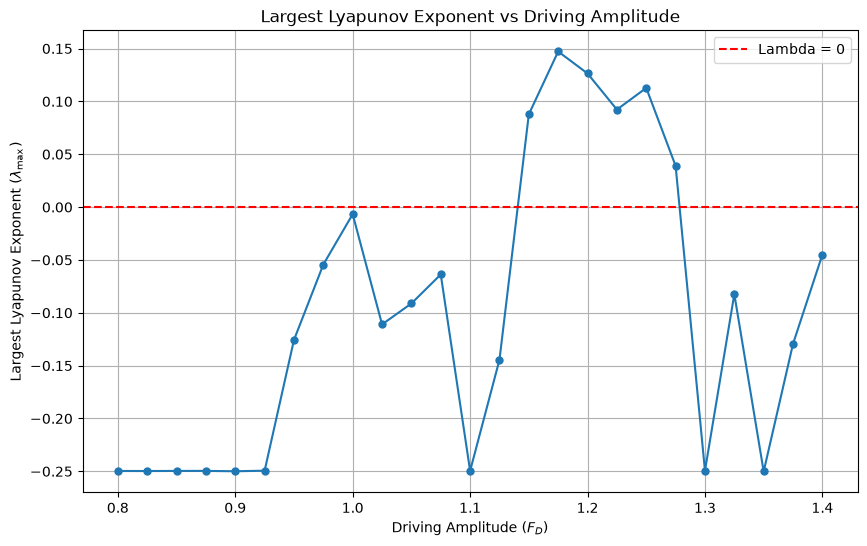

In [37]:
plt.figure(figsize=(10, 6))

plt.plot(
    F_D_values,
    lyapunov_values,
    marker="o",
    markersize=5,
    linewidth=1.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Lambda = 0"
)

plt.xlabel(r"Driving Amplitude ($F_D$)")
plt.ylabel(r"Largest Lyapunov Exponent ($\lambda_{\max}$)")
plt.title("Largest Lyapunov Exponent vs Driving Amplitude")

plt.grid(True)
plt.legend()
plt.show()

In [38]:
F_D_fine = np.linspace(1.10, 1.17, 15)

lyapunov_fine = []

for F in F_D_fine:

    exponents = calculate_full_lyapunov_spectrum(
        q=q,
        F_D=F,
        Omega_D=Omega_D,
        initial_state=[0.2, 0.0],
        transient_time=2000.0,
        total_time=10000.0,
        renorm_time=0.05
    )

    lyapunov_fine.append(exponents[0])

    print(
        f"F_D = {F:.4f}, "
        f"Lambda_max = {exponents[0]:.6f}"
    )

F_D = 1.1000, Lambda_max = -0.249893
F_D = 1.1050, Lambda_max = 0.076784
F_D = 1.1100, Lambda_max = -0.249829
F_D = 1.1150, Lambda_max = -0.192378
F_D = 1.1200, Lambda_max = -0.160048
F_D = 1.1250, Lambda_max = -0.144590
F_D = 1.1300, Lambda_max = -0.142447
F_D = 1.1350, Lambda_max = -0.163574
F_D = 1.1400, Lambda_max = -0.250066
F_D = 1.1450, Lambda_max = -0.099241
F_D = 1.1500, Lambda_max = 0.098880
F_D = 1.1550, Lambda_max = 0.119154
F_D = 1.1600, Lambda_max = 0.130830
F_D = 1.1650, Lambda_max = 0.143628
F_D = 1.1700, Lambda_max = 0.148934


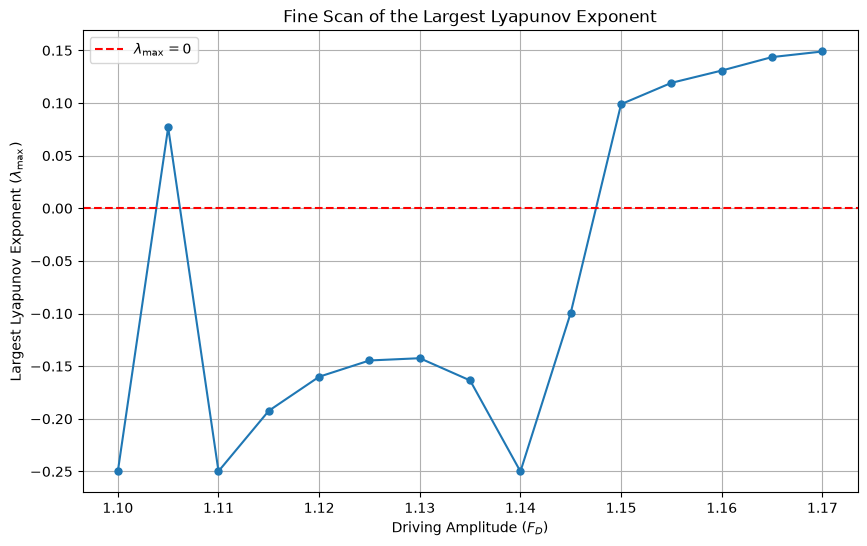

In [39]:
plt.figure(figsize=(10, 6))

plt.plot(
    F_D_fine,
    lyapunov_fine,
    marker="o",
    markersize=5,
    linewidth=1.5
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label=r"$\lambda_{\max}=0$"
)

plt.xlabel(r"Driving Amplitude ($F_D$)")
plt.ylabel(r"Largest Lyapunov Exponent ($\lambda_{\max}$)")
plt.title("Fine Scan of the Largest Lyapunov Exponent")

plt.grid(True)
plt.legend()
plt.show()

In [10]:
q = 0.5
F_D = 1.2
Omega_D = 2 / 3

initial_state = [0.2, 0.0]

In [12]:
import numpy as np

In [14]:
print("q =", q)
print("F_D =", F_D)
print("Omega_D =", Omega_D)
print("NumPy version:", np.__version__)

q = 0.5
F_D = 1.2
Omega_D = 0.6666666666666666
NumPy version: 2.5.4


In [16]:
from scipy.integrate import solve_ivp

In [18]:
def driven_pendulum(t, y, q, F_D, Omega_D):
    theta, omega = y

    dtheta_dt = omega

    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    return [dtheta_dt, domega_dt]

In [19]:
def full_variational_system(t, Y, q, F_D, Omega_D):

    theta, omega = Y[:2]

    V = Y[2:].reshape((2, 2))

    dtheta_dt = omega

    domega_dt = (
        -q * omega
        - np.sin(theta)
        + F_D * np.cos(Omega_D * t)
    )

    J = np.array([
        [0.0, 1.0],
        [-np.cos(theta), -q]
    ])

    dV_dt = J @ V

    return np.concatenate((
        [dtheta_dt, domega_dt],
        dV_dt.flatten()
    ))

In [20]:
test_exponents = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.2,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=100.0,
    total_time=200.0,
    renorm_time=0.05
)

print(test_exponents)

[ 0.13229288 -0.63229288]


In [21]:
exponents_1105 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.105,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.105")
print("Lambda 1 =", exponents_1105[0])
print("Lambda 2 =", exponents_1105[1])
print("Sum      =", np.sum(exponents_1105))

F_D = 1.105
Lambda 1 = 0.07761078290973673
Lambda 2 = -0.5776107829088676
Sum      = -0.49999999999913086


In [22]:
exponents_1110 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.110,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.110")
print("Lambda 1 =", exponents_1110[0])
print("Lambda 2 =", exponents_1110[1])
print("Sum      =", np.sum(exponents_1110))

F_D = 1.110
Lambda 1 = -0.24995632526151718
Lambda 2 = -0.2500436747379038
Sum      = -0.49999999999942096


In [23]:
exponents_11075 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.1075,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.1075")
print("Lambda 1 =", exponents_11075[0])
print("Lambda 2 =", exponents_11075[1])
print("Sum      =", np.sum(exponents_11075))

F_D = 1.1075
Lambda 1 = 0.08630374961729945
Lambda 2 = -0.5863037496164416
Sum      = -0.49999999999914213


In [24]:
exponents_110875 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.10875,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.10875")
print("Lambda 1 =", exponents_110875[0])
print("Lambda 2 =", exponents_110875[1])
print("Sum      =", np.sum(exponents_110875))

F_D = 1.10875
Lambda 1 = 0.09254761453996561
Lambda 2 = -0.5925476145390922
Sum      = -0.4999999999991266


In [25]:
exponents_1109375 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.109375,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.109375")
print("Lambda 1 =", exponents_1109375[0])
print("Lambda 2 =", exponents_1109375[1])
print("Sum      =", np.sum(exponents_1109375))

F_D = 1.109375
Lambda 1 = -0.24994227369010086
Lambda 2 = -0.2500577263093371
Sum      = -0.49999999999943795


In [26]:
exponents_11090625 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.1090625,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.1090625")
print("Lambda 1 =", exponents_11090625[0])
print("Lambda 2 =", exponents_11090625[1])
print("Sum      =", np.sum(exponents_11090625))

F_D = 1.1090625
Lambda 1 = 0.0923631382329826
Lambda 2 = -0.5923631382321107
Sum      = -0.49999999999912814


In [27]:
exponents_110921875 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.10921875,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.10921875")
print("Lambda 1 =", exponents_110921875[0])
print("Lambda 2 =", exponents_110921875[1])
print("Sum      =", np.sum(exponents_110921875))

F_D = 1.10921875
Lambda 1 = 0.09421006324377913
Lambda 2 = -0.5942100632428862
Sum      = -0.49999999999910705


In [28]:
exponents_1109296875 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.109296875,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.109296875")
print("Lambda 1 =", exponents_1109296875[0])
print("Lambda 2 =", exponents_1109296875[1])
print("Sum      =", np.sum(exponents_1109296875))

F_D = 1.109296875
Lambda 1 = -0.24993423970201642
Lambda 2 = -0.2500657602974135
Sum      = -0.4999999999994299


In [29]:
exponents_11092578125 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.1092578125,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.1092578125")
print("Lambda 1 =", exponents_11092578125[0])
print("Lambda 2 =", exponents_11092578125[1])
print("Sum      =", np.sum(exponents_11092578125))

F_D = 1.1092578125
Lambda 1 = 0.0941563925300578
Lambda 2 = -0.5941563925291822
Sum      = -0.49999999999912437


In [30]:
exponents_110927734375 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.10927734375,
    Omega_D=Omega_D,
    initial_state=[0.2, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.10927734375")
print("Lambda 1 =", exponents_110927734375[0])
print("Lambda 2 =", exponents_110927734375[1])
print("Sum      =", np.sum(exponents_110927734375))

F_D = 1.10927734375
Lambda 1 = -0.24993270359794317
Lambda 2 = -0.250067296401488
Sum      = -0.4999999999994312


In [31]:
exponents_new_ic = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.1092578125,
    Omega_D=Omega_D,
    initial_state=[0.3, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.1092578125")
print("Initial state = [0.3, 0.0]")
print("Lambda 1 =", exponents_new_ic[0])
print("Lambda 2 =", exponents_new_ic[1])
print("Sum      =", np.sum(exponents_new_ic))

F_D = 1.1092578125
Initial state = [0.3, 0.0]
Lambda 1 = -0.24996318174154822
Lambda 2 = -0.25003681825787943
Sum      = -0.4999999999994277


In [32]:
exponents_ic_025 = calculate_full_lyapunov_spectrum(
    q=q,
    F_D=1.1092578125,
    Omega_D=Omega_D,
    initial_state=[0.25, 0.0],
    transient_time=5000.0,
    total_time=30000.0,
    renorm_time=0.05
)

print("F_D = 1.1092578125")
print("Initial state = [0.25, 0.0]")
print("Lambda 1 =", exponents_ic_025[0])
print("Lambda 2 =", exponents_ic_025[1])
print("Sum      =", np.sum(exponents_ic_025))

F_D = 1.1092578125
Initial state = [0.25, 0.0]
Lambda 1 = -0.24996318174340135
Lambda 2 = -0.2500368182560189
Sum      = -0.49999999999942024


In [33]:
theta_initial_values = np.linspace(0.20, 0.30, 21)

print("Number of initial conditions:", len(theta_initial_values))
print(theta_initial_values)

Number of initial conditions: 21
[0.2   0.205 0.21  0.215 0.22  0.225 0.23  0.235 0.24  0.245 0.25  0.255
 0.26  0.265 0.27  0.275 0.28  0.285 0.29  0.295 0.3  ]


In [34]:
lyapunov_initial_conditions = []

for theta_0 in theta_initial_values:
    exponents = calculate_full_lyapunov_spectrum(
        q=q,
        F_D=1.1092578125,
        Omega_D=Omega_D,
        initial_state=[theta_0, 0.0],
        transient_time=5000.0,
        total_time=30000.0,
        renorm_time=0.05
    )

    lyapunov_initial_conditions.append(exponents[0])

    print(
        f"theta_0 = {theta_0:.3f}, "
        f"Lambda_max = {exponents[0]:.6f}"
    )

theta_0 = 0.200, Lambda_max = 0.094156
theta_0 = 0.205, Lambda_max = 0.095133
theta_0 = 0.210, Lambda_max = 0.093788
theta_0 = 0.215, Lambda_max = 0.093521
theta_0 = 0.220, Lambda_max = 0.094668
theta_0 = 0.225, Lambda_max = 0.094842
theta_0 = 0.230, Lambda_max = 0.093715
theta_0 = 0.235, Lambda_max = 0.094661
theta_0 = 0.240, Lambda_max = 0.094402
theta_0 = 0.245, Lambda_max = 0.094709
theta_0 = 0.250, Lambda_max = -0.249963
theta_0 = 0.255, Lambda_max = -0.249933
theta_0 = 0.260, Lambda_max = -0.249928
theta_0 = 0.265, Lambda_max = -0.249933
theta_0 = 0.270, Lambda_max = 0.094781
theta_0 = 0.275, Lambda_max = -0.249963
theta_0 = 0.280, Lambda_max = -0.249963
theta_0 = 0.285, Lambda_max = -0.249963
theta_0 = 0.290, Lambda_max = -0.249963
theta_0 = 0.295, Lambda_max = -0.249963
theta_0 = 0.300, Lambda_max = -0.249963


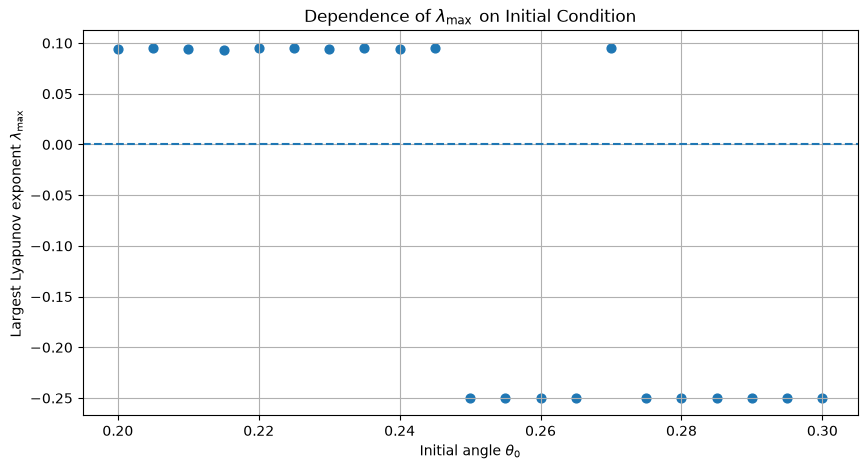

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    theta_initial_values,
    lyapunov_initial_conditions,
    s=40
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel(r"Initial angle $\theta_0$")
plt.ylabel(r"Largest Lyapunov exponent $\lambda_{\max}$")
plt.title(r"Dependence of $\lambda_{\max}$ on Initial Condition")
plt.grid(True)

plt.show()

In [36]:
theta_fine = np.arange(0.265, 0.2701, 0.001)

for theta_0 in theta_fine:
    exponents = calculate_full_lyapunov_spectrum(
        q=q,
        F_D=1.1092578125,
        Omega_D=Omega_D,
        initial_state=[theta_0, 0.0],
        transient_time=5000.0,
        total_time=30000.0,
        renorm_time=0.05
    )

    print(
        f"theta_0 = {theta_0:.3f}, "
        f"Lambda_max = {exponents[0]:.6f}"
    )

theta_0 = 0.265, Lambda_max = -0.249933
theta_0 = 0.266, Lambda_max = 0.094798
theta_0 = 0.267, Lambda_max = 0.094008
theta_0 = 0.268, Lambda_max = 0.094888
theta_0 = 0.269, Lambda_max = 0.094216
theta_0 = 0.270, Lambda_max = 0.094781


In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

q = 0.5
F_D = 1.1092578125
Omega_D = 2 / 3

T_D = 2 * np.pi / Omega_D

transient_time = 1000.0
num_points = 1500


def compute_poincare(theta_0):
    sampling_times = (
        transient_time
        + np.arange(1, num_points + 1) * T_D
    )

    sol = solve_ivp(
        driven_pendulum,
        (0, sampling_times[-1]),
        [theta_0, 0.0],
        args=(q, F_D, Omega_D),
        t_eval=sampling_times,
        rtol=1e-9,
        atol=1e-11
    )

    if not sol.success:
        raise RuntimeError(sol.message)

    theta = sol.y[0]
    omega = sol.y[1]

    theta_wrapped = (
        (theta + np.pi) % (2 * np.pi)
        - np.pi
    )

    return theta_wrapped, omega


theta_regular, omega_regular = compute_poincare(0.265)
theta_chaotic, omega_chaotic = compute_poincare(0.266)

print("Regular points:", len(theta_regular))
print("Chaotic points:", len(theta_chaotic))

Regular points: 1500
Chaotic points: 1500


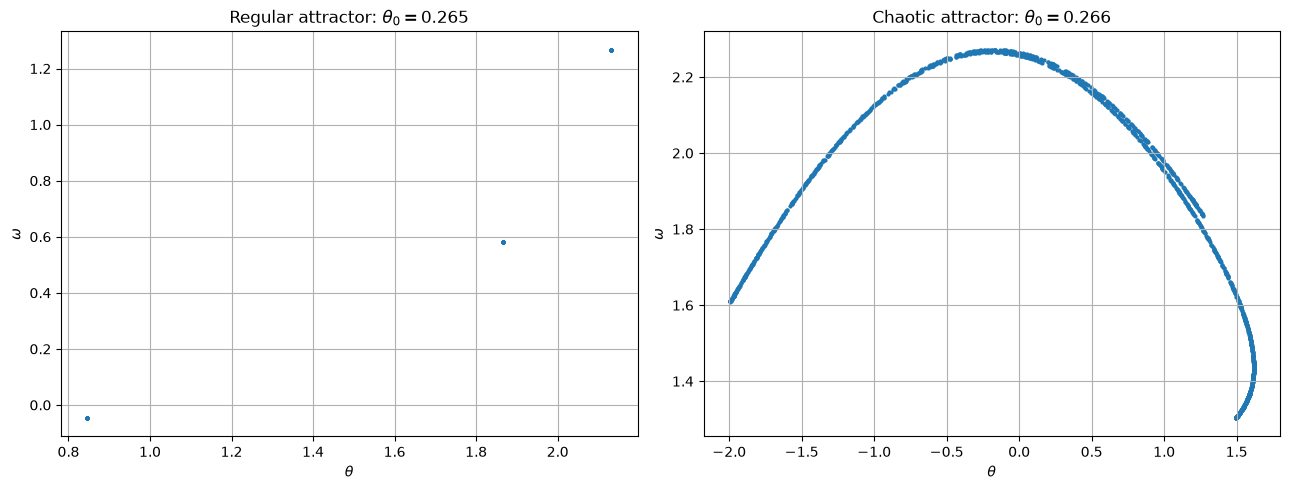

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Regular attractor
axes[0].scatter(
    theta_regular,
    omega_regular,
    s=4
)
axes[0].set_xlabel(r"$\theta$")
axes[0].set_ylabel(r"$\omega$")
axes[0].set_title(r"Regular attractor: $\theta_0=0.265$")
axes[0].grid(True)

# Chaotic attractor
axes[1].scatter(
    theta_chaotic,
    omega_chaotic,
    s=4
)
axes[1].set_xlabel(r"$\theta$")
axes[1].set_ylabel(r"$\omega$")
axes[1].set_title(r"Chaotic attractor: $\theta_0=0.266$")
axes[1].grid(True)

plt.tight_layout()
plt.show()